In [1]:
import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.mplot3d import Axes3D
import os

# calculating $v_{N\to Q}$ given $a_N, \mu_Q, T, a_{Q^*}$

In [2]:
def vNtoQ(aN, muQ, T, aQ):
    # Compute intermediate quantities
    etaQ = (9 * np.pi**2 * T**2) / muQ**2
    tauQ = 1.98e12 * ((300 / muQ)**5)
    DQ = (np.pi / (24 * (0.3)**2 * 1.81 * T**(5/3))) * ((6 * 0.3 / np.pi * muQ**2)**(1/3))
    # Compute v_N->Q
    vNQ = np.sqrt((DQ / tauQ) * ((aQ**4 + 2 * etaQ * aQ**2) / (2 * aN * (aN - aQ)))) * 3e8
    return vNQ # in (m/s)


def vNtoQ_only_a3(aN, muQ, T, aQ):
    # Compute intermediate quantities
    tauQ = 1.98e12 * ((300 / muQ)**5)
    DQ = (np.pi / (24 * (0.3)**2 * 1.81 * T**(5/3))) * ((6 * 0.3 / np.pi * muQ**2)**(1/3))
    # Compute v_N->Q
    vNQ = np.sqrt((DQ / tauQ) * ((aQ**4) / (2 * aN * (aN - aQ)))) * 3e8
    return vNQ # in (m/s))


def vNtoQ_only_eta_a(aN, muQ, T, aQ):
    # Compute intermediate quantities
    etaQ = (9 * np.pi**2 * T**2) / muQ**2
    tauQ = 1.98e12 * ((300 / muQ)**5)
    DQ = (np.pi / (24 * (0.3)**2 * 1.81 * T**(5/3))) * ((6 * 0.3 / np.pi * muQ**2)**(1/3))
    # Compute v_N->Q
    vNQ = np.sqrt((DQ / tauQ) * ((2 * etaQ * aQ**2) / (2 * aN * (aN - aQ)))) * 3e8
    return vNQ # in (m/s)

In [3]:
x = vNtoQ(1, 360, 10, 0.1)
print(x)

8.200541317719843


# Plotting

In [4]:
plt.rcParams["figure.dpi"] = 150

In [5]:
aN = 1
muQ = 360
Num = 50
T = np.linspace(1, 100, Num)
aQ = np.linspace(0.01, 0.5, Num)

T_grid, aQ_grid = np.meshgrid(T, aQ)
v = vNtoQ(aN, muQ, T_grid, aQ_grid)

#v_only_a3 = vNtoQ_only_a3(aN, muQ, T_grid, aQ_grid))
#v_only_eta_a = np.log10(vNtoQ_only_eta_a(aN, muQ, T_grid, aQ_grid))

contour

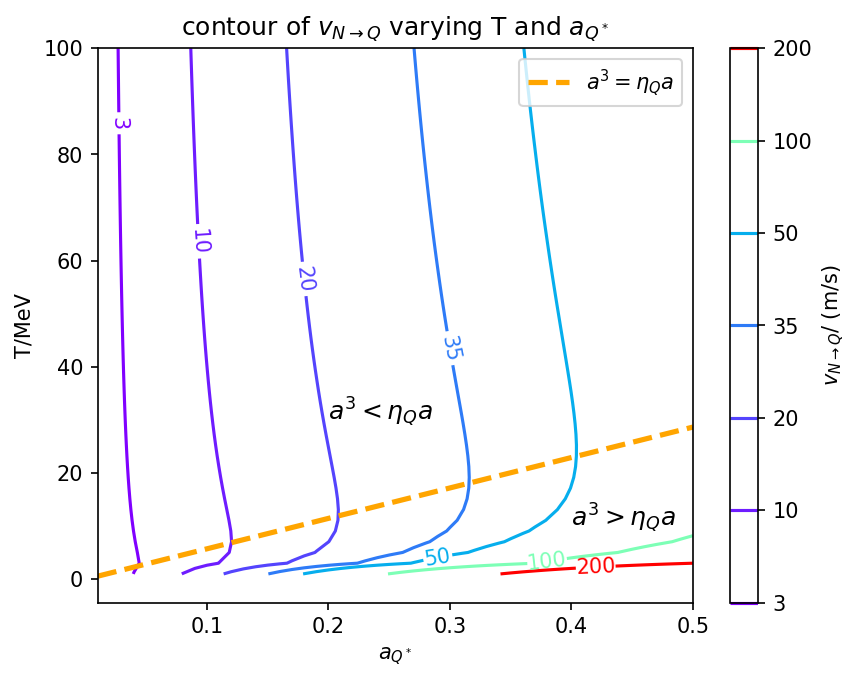

In [6]:
contours = plt.contour(aQ_grid, T_grid, v, levels=[3, 10, 20, 35, 50, 100, 200], cmap='rainbow')
plt.clabel(contours, inline=True, fontsize=10)
plt.plot(aQ, muQ*aQ/(2*np.pi), linestyle='--', lw=2.5, label=r"$a^3 = \eta_Q a$", color='orange')
plt.title(r"contour of $v_{N\to Q}$ varying T and $a_{Q^*}$")
plt.xlabel(r"$a_{Q^*}$")
plt.ylabel("T/MeV")
plt.colorbar(label=r'$v_{N\to Q}$/ (m/s)')
plt.legend()
plt.text(0.2, 30, r"$a^3<\eta_Q a$", fontsize=12)
plt.text(0.4, 10, r"$a^3>\eta_Q a$", fontsize=12)

# Define the path to the Downloads folder
downloads_path = os.path.expanduser("/Users/janshao/Downloads/")

# Save the figure
plt.savefig(os.path.join(downloads_path, "test.png"), dpi=300)  # Increase DPI as needed

plt.show()

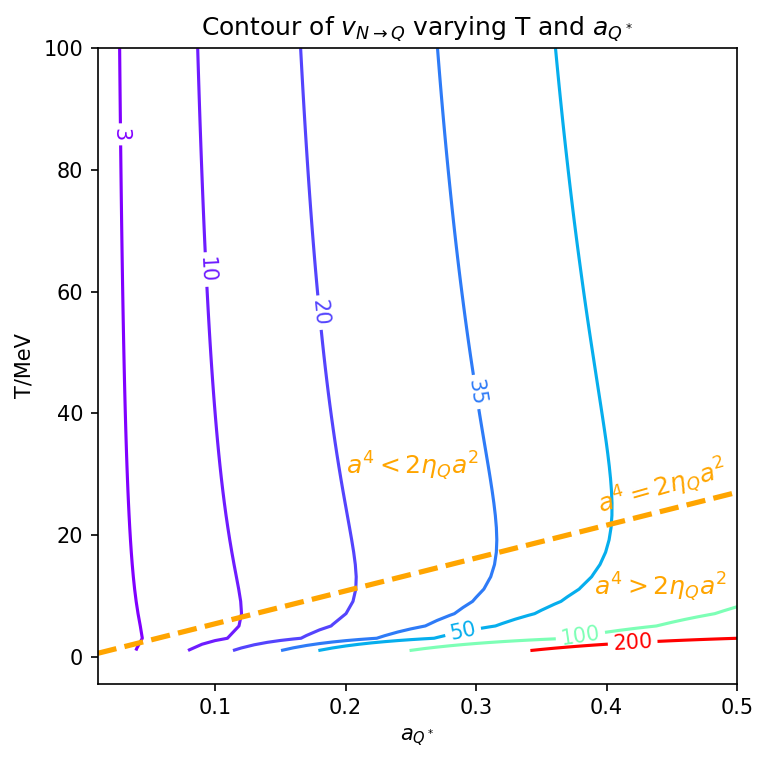

In [7]:
aN = 1
muQ = 360
Num = 50
T = np.linspace(1, 100, Num)
aQ = np.linspace(0.01, 0.5, Num)

T_grid, aQ_grid = np.meshgrid(T, aQ)

v = vNtoQ(aN, muQ, T_grid, aQ_grid)  

plt.figure(figsize=[5.5, 5.5])
contours = plt.contour(aQ_grid, T_grid, v, levels=[3, 10, 20, 35, 50, 100, 200], cmap='rainbow')
plt.clabel(contours, inline=True, fontsize=10)

y_values = (np.sqrt(2) * muQ * aQ) / (3 * np.pi)  # T values corresponding to aQ

plt.plot(aQ, y_values, linestyle='--', lw=2.5, color='orange')
x_text = 0.39
y_text = (np.sqrt(2) * muQ * x_text) / (3 * np.pi)  + 1
plt.text(x_text, y_text, r"$a^4 = 2\eta_Q a^2$", fontsize=12, color='orange',
         rotation=16, verticalalignment='bottom')

plt.title(r"Contour of $v_{N\to Q}$ varying T and $a_{Q^*}$")
plt.xlabel(r"$a_{Q^*}$")
plt.ylabel("T/MeV")
#plt.colorbar(label=r'$v_{N\to Q}$/ (m/s)')

plt.text(0.2, 30, r"$a^4<2\eta_Q a^2$", fontsize=12, color='orange')
plt.text(0.39, 10, r"$a^4>2\eta_Q a^2$", fontsize=12, color='orange')

downloads_path = os.path.expanduser("/Users/janshao/Downloads/")

# Save the figure
plt.savefig(os.path.join(downloads_path, "tst.png"), dpi=300)  # Increase DPI as needed

plt.show()

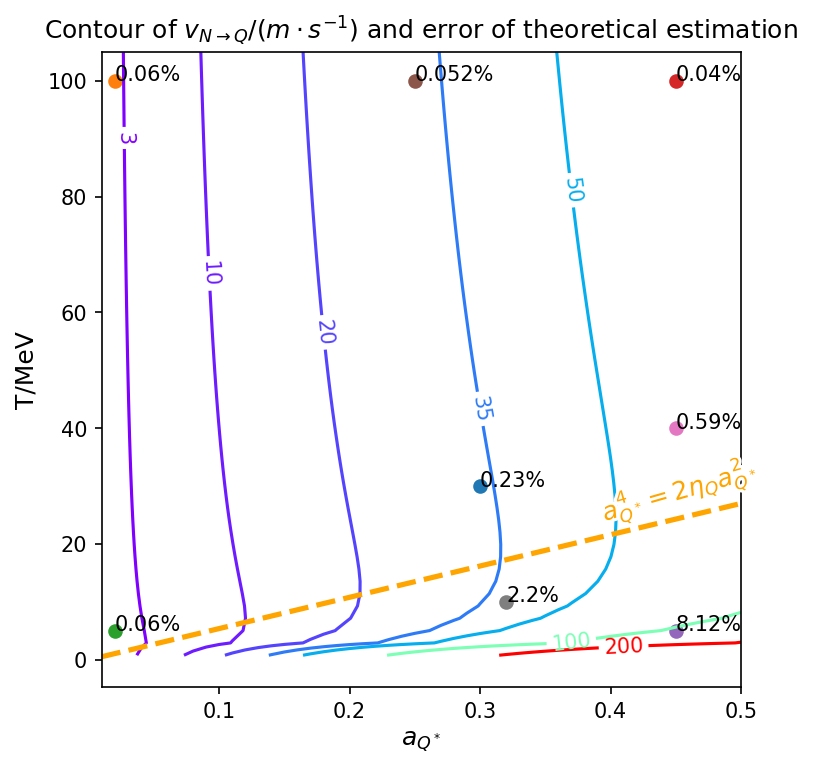

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import os
import matplotlib.patheffects as patheffects

# Given parameters
aN = 1
muQ = 360
Num = 50
T = np.linspace(0.8, 105, Num)
aQ = np.linspace(0.01, 0.5, Num)

# Create grid for contour plot
T_grid, aQ_grid = np.meshgrid(T, aQ)

# Compute function values (assuming vNtoQ is defined)
v = vNtoQ(aN, muQ, T_grid, aQ_grid)

# Create figure with a square figure size
plt.figure(figsize=[5.5, 5.5])

# Create contour plot
contours = plt.contour(aQ_grid, T_grid, v, levels=[3, 10, 20, 35, 50, 100, 200], cmap='rainbow')
plt.clabel(contours, inline=True, fontsize=10)

# Compute the orange dashed line (with updated formula for T values)
y_values = (np.sqrt(2) * muQ * aQ) / (3 * np.pi)  # T values corresponding to aQ

# Plot the orange dashed line
plt.plot(aQ, y_values, linestyle='--', lw=2.5, color='orange')

# Define the text position for the equation
x_text = 0.39
y_text = (np.sqrt(2) * muQ * x_text) / (3 * np.pi) + 1  # Adjust for correct placement

# Add text near the orange line with the proper alignment
text = plt.text(x_text, y_text, r"$a_{Q^*}^4 = 2\eta_Q a_{Q^*}^2$", fontsize=12, color='orange',
                rotation=16, verticalalignment='bottom', horizontalalignment='left')

# Apply path effects to the text to hide the contour line behind it
text.set_path_effects([
    patheffects.withStroke(linewidth=3, foreground='white')  # White background around text to hide contour line
])

# Title and axis labels
plt.title(r"Contour of $v_{N\to Q}/(m\cdot s^{-1})$ and error of theoretical estimation")
plt.xlabel(r"$a_{Q^*}$", fontsize=12)
plt.ylabel("T/MeV", fontsize=12)

plt.scatter(0.3, 30) 
plt.text(0.3, 30, "0.23%")
plt.scatter(0.02, 100)
plt.text(0.02, 100, "0.06%")
plt.scatter(0.02, 5)
plt.text(0.02, 5, "0.06%")
plt.scatter(0.45, 100)
plt.text(0.45, 100, "0.04%")
plt.scatter(0.45, 5)
plt.text(0.45, 5, "8.12%")
plt.scatter(0.25, 100)
plt.text(0.25, 100, "0.052%")
plt.scatter(0.45, 40)
plt.text(0.45, 40, "0.59%")
plt.scatter(0.32, 10)
plt.text(0.32, 10, "2.2%")

# Additional annotations (text in orange)
#text2 = plt.text(0.2, 30, r"$a_{Q^*}^4<2\eta_Q a_{Q^*}^2$", fontsize=12, color='orange')
#text3 = plt.text(0.39, 10, r"$a_{Q^*}^4>2\eta_Q a_{Q^*}^2$", fontsize=12, color='orange')
#text2.set_path_effects([
#    patheffects.withStroke(linewidth=3, foreground='white')  # White background around text to hide contour line
#])
#text3.set_path_effects([
#    patheffects.withStroke(linewidth=3, foreground='white')  # White background around text to hide contour line
#])

# Define the path to the Downloads folder
downloads_path = os.path.expanduser("/Users/janshao/Downloads/")

# Save the figure
plt.savefig(os.path.join(downloads_path, "contour_sample_points.pdf"), dpi=300)

# Show the plot
plt.show()

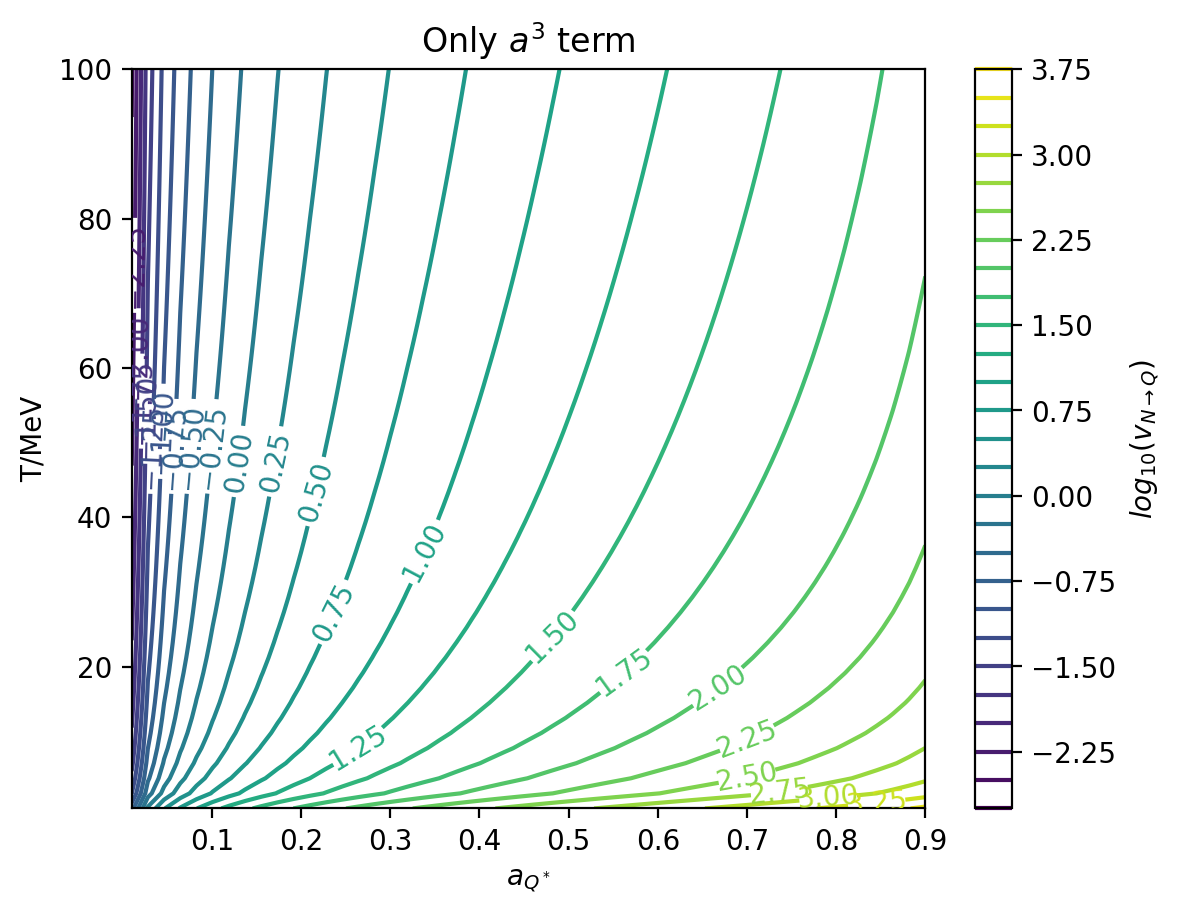

In [39]:
contours = plt.contour(aQ_grid, T_grid, v_only_a3, levels=25, cmap='viridis')
plt.clabel(contours, inline=True, fontsize=10)
plt.title(r"Only $a^3$ term")
plt.xlabel(r"$a_{Q^*}$")
plt.ylabel("T/MeV")
plt.colorbar(label=r'$log_{10}(v_{N\to Q})$')

# Define the path to the Downloads folder
downloads_path = os.path.expanduser("/Users/janshao/Downloads/")

# Save the figure
plt.savefig(os.path.join(downloads_path, "contour_only_a3_a_to_0.9.png"), dpi=300)  # Increase DPI as needed

plt.show()

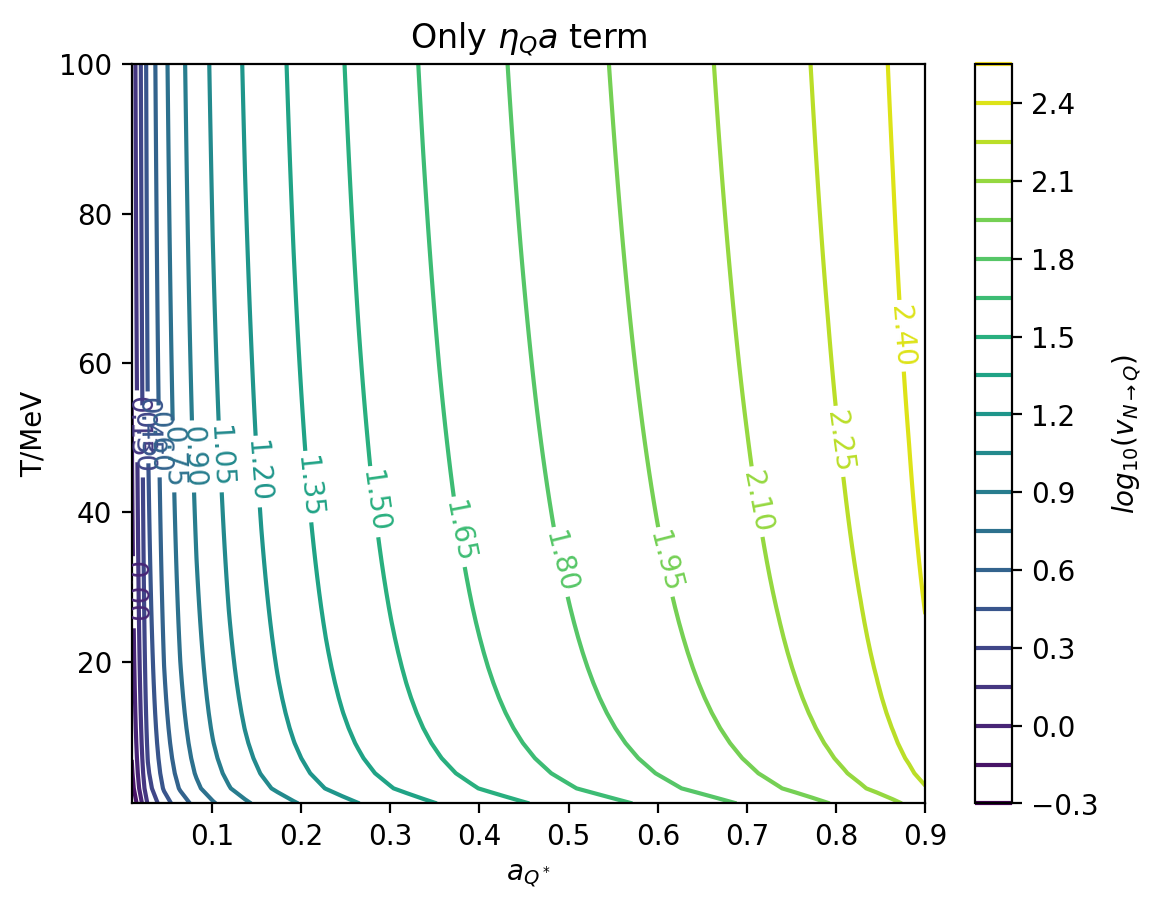

In [40]:
contours = plt.contour(aQ_grid, T_grid, v_only_eta_a, levels=20, cmap='viridis')
plt.clabel(contours, inline=True, fontsize=10)
plt.title(r"Only $\eta_Q a$ term")
plt.xlabel(r"$a_{Q^*}$")
plt.ylabel("T/MeV")
plt.colorbar(label=r'$log_{10}(v_{N\to Q})$')

# Define the path to the Downloads folder
downloads_path = os.path.expanduser("/Users/janshao/Downloads/")

# Save the figure
plt.savefig(os.path.join(downloads_path, "contour_only_eta_a_a_to_0.9.png"), dpi=300)  # Increase DPI as needed

plt.show()

plot-3D

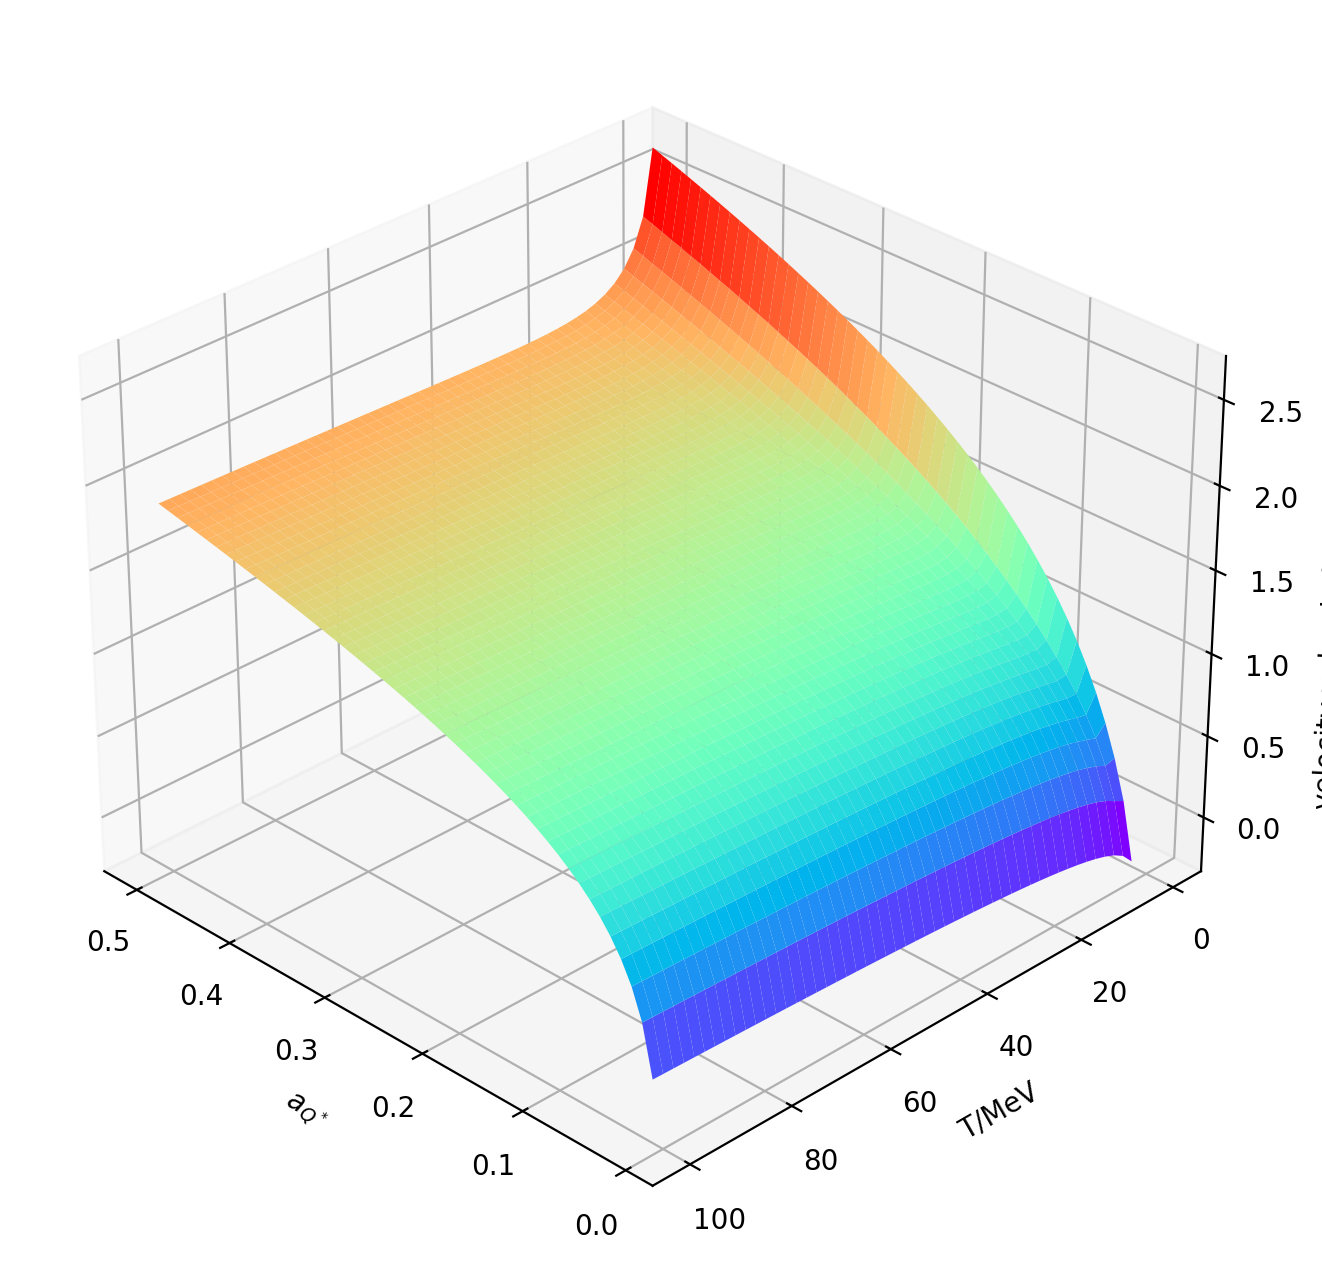

In [27]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot the surface
ax.plot_surface(aQ_grid, T_grid, v, cmap='rainbow')

# Add labels and a title
ax.set_xlabel(r"$a_{Q^*}$")
ax.set_ylabel("T/MeV")
ax.set_zlabel('velocity value in lg(x) scale')
#ax.set_title()
ax.view_init(elev=30, azim=135)

In [41]:
40 * 90 / 3600

1.0

# prior to Mar.27 $\mu_K-\mu_B$ plain

$$
\Delta P = P_{QM}-P_{NM} = \frac{3\left(\mu_u^4 + \mu_d^4 + \mu_s^4\right)}{12 \pi^2} - \frac{\mu_B^4}{12\pi^2} = \frac{3}{12 \pi^2} \left( \left( \frac{\mu_B}{3} + \frac{\mu_K}{2} \right)^4 + \left( \frac{\mu_B}{3} - \frac{\mu_K}{2} \right)^4 + \left( \frac{\mu_B}{3} \right)^4 \right) - \frac{\mu_B^4}{12 \pi^2}
$$

which can not be correct since in this case, the slope $\partial P/\partial\mu_B$ for NM is larger than that for QM, so question-1: what's the correct $P_{NM}$ as function of baryon chemical potential $\mu_B$?

to acconut for this problem, another way is that the total pressure of QM and NM have contributions from gluons and pions as well; 

$$
P_{fermion} = 2T\int \frac{d^3k}{(2\pi)^3} \ln\left[ 1+e^{-\frac{\omega-\mu}{T}} \right]\overset{T=0}{\longrightarrow} P_f(\mu) = -\frac{T^4}{\pi^2}Li_4\left(-e^{\frac{\mu}{T}}\right)
$$

$$
P_{boson} = -2T\int \frac{d^3k}{(2\pi)^3} \ln\left[ 1-e^{-\frac{\omega-\mu}{T}} \right]\overset{T=0}{\longrightarrow} P_b(\mu) = \frac{T^4}{\pi^2}Li_4\left(e^{\frac{\mu}{T}}\right)
$$

Since there're 3 pions and 2 nucleons in NM; and 8 gluons and 3 quarks in QM, we have:
$$
P_{NM} = 3P_b(\mu_\pi) + 2P_f(\mu_B)
$$

$$
P_{QM} = 8P_b(\mu_g) + 9P_f(\mu_q)
$$

$P_{NM}$ isn't a good approximation at all, around 300 MeV, nucleon mass shouldn't be ignored; use Schmitt's equation; 

Text(0, 0.5, '$\\mu_K$')

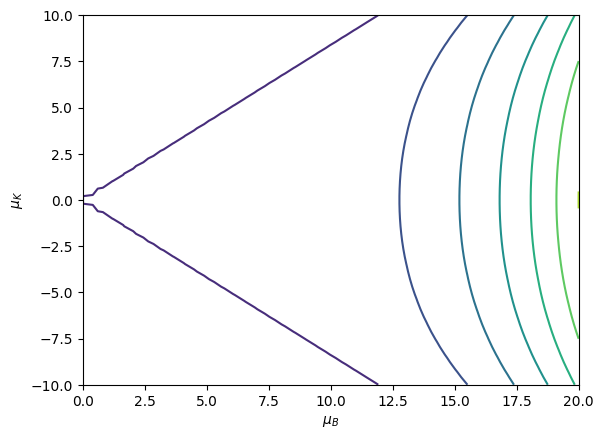

In [20]:
import numpy as np
import matplotlib.pyplot as plt

muK = np.linspace(-10,10,50)
muB = np.linspace(0,20,50)

muK_grid, muB_grid = np.meshgrid(muK, muB)

P = ((muB_grid/3 + muK_grid/2)**4 + (muB_grid/3 - muK_grid/2)**4 + (muB_grid/3)**4) * 3/(12*np.pi**2) - (muB_grid)**4/(1*12*np.pi**2)
#P = (muB_grid/3 + muK_grid/2)**4 + (muB_grid/3 - muK_grid/2)**4

plt.contour(muB_grid, muK_grid, -P)
plt.xlabel(r"$\mu_B$")
plt.ylabel(r"$\mu_K$")

# Prior to Apr.4

### First get the isobar with correct shape

The EOS for NM: $P_{NM} = \frac{\mu_B^4}{12\pi^2}$ is a very bad approximation since $T\sim 100MeV$, and nucleon mass $m_B\sim 939MeV$. Consider the following non-interacting $T=0$ NM model. 

first, for a fermion, it's pressure $P_{fermion} \equiv P_f$ is the following in $T=0$ limit, where $\mu = \sqrt{k_F^2 + m^2}$
$$
\begin{aligned}
P_f(\mu) & = \mu n - \epsilon =  \frac{1}{\pi^2}\int_{0}^{k_F} k^2\left( \mu - \sqrt{k^2 + m^2} \right) dk \\
& = \frac{1}{24\pi^2}\left[ (2k_F^3 - 3m^2k_F)\mu + 3m^4\ln\frac{k_F + \mu}{m} \right]
\end{aligned}
$$

therefore, for NM composed of protons, neutrons, and electrons, whose pressure we ignore, the total pressure is the sum of proton pressure and neutron pressure, which is a function of $\mu_p$ and $\mu_n$:
$$
P_{NM} = P_f(\mu_p) + P_f(\mu_n) = P_n + P_p
$$

next, convert everything to baryon number and baryon chemical potential. note that $n_B = n_n + n_p$, and the following:
$$
n_B = \frac{\partial P_{NM}}{\partial \mu_B} = \frac{\partial (P_n + P_p)}{\partial \mu_p}\frac{\partial\mu_p}{\partial\mu_B} + \frac{\partial (P_n + P_p)}{\partial \mu_n}\frac{\partial\mu_n}{\partial\mu_B} = n_p\frac{\partial\mu_p}{\partial\mu_B} + n_n\frac{\partial\mu_n}{\partial\mu_B} = n_p + n_n
$$
therefore, we have $\frac{\partial\mu_p}{\partial\mu_B} = \frac{\partial\mu_n}{\partial\mu_B} = 1$, hence $\mu_B = \mu_n + \mu_p$.

*{this above derivation is wrong}*

in addition, for $\beta$ equilibriated NM, we have $\mu_n = \mu_p + \mu_e$, which implies $\mu_n - \mu_p = \mu_e$, hence we have:
$$
\left\{
\begin{aligned}
& \mu_n = \frac{1}{2}(\mu_B + \mu_e) \\
& \mu_p = \frac{1}{2}(\mu_B - \mu_e) \\
\end{aligned}
\right.
$$
Plug this in $P_{NM} = P_n + P_p$, we have: $P_{NM} = P_f\left(\frac{\mu_B + \mu_e}{2}\right) + P_f\left(\frac{\mu_B - \mu_e}{2}\right)$. 

First, we can ignore $\mu_e$ and see what we got. This approximation holds for small baryon chemical potential not much higher than $m_B\simeq 939MeV$, this is because for neutralality, we must have $n_p = n_e$, which implies $k_{F,p} = k_{F,e}$, hence
$$
\frac{\mu_e}{\mu_p} = \sqrt{\frac{m_e^2 + k^2}{m_p^2 + k^2}}
$$
if $k$ is much smaller than $m_p$, then since $m_e$ is a thousand times smaller than $m_p$, it's safe to ignore $\mu_e$. This is a good approximation aronud $k=0$, which implies that $\mu_B\sim\mu_p\sim{m_p}\sim 939MeV$

So we take $P_{NM} = 2P_f\left(\frac{\mu_B}{2}\right)$

In [4]:
def P_f(mu, m):
    k_F = np.sqrt(mu**2 - m**2)
    return ( (2*k_F**3 - 3*m**2*k_F)*mu + 3*m**4*np.log((k_F+mu)/m) )/(24*np.pi**2)

Text(0, 0.5, '$\\mu_K$')

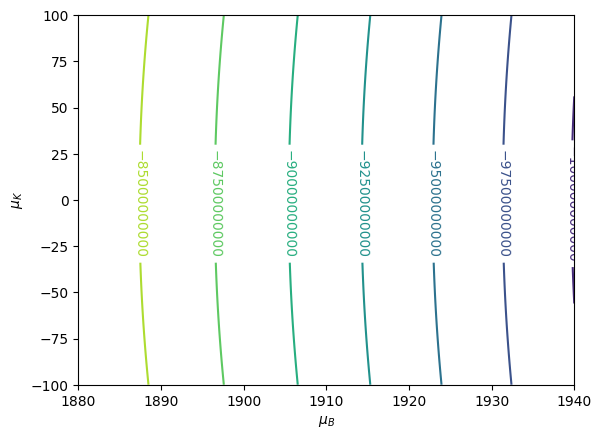

In [53]:
import numpy as np
import matplotlib.pyplot as plt

muK = np.linspace(-100,100,50)
muB = np.linspace(940*2,940*2+60,50)

muK_grid, muB_grid = np.meshgrid(muK, muB)

P_QM = ((muB_grid/3 + muK_grid/2)**4 + (muB_grid/3 - muK_grid/2)**4 + (muB_grid/3)**4) * 3/(12*np.pi**2) #- (muB_grid)**4/(1*12*np.pi**2)
P_NM = 2*P_f(muB_grid, m=939)

contours = plt.contour(muB_grid, muK_grid, P_QM - P_NM)
plt.clabel(contours, inline=True, fontsize=10)

plt.xlabel(r"$\mu_B$")
plt.ylabel(r"$\mu_K$")

### Then try to see if it's possible that Eq.(35) holds while Eq.(38) doesn't

First, in the paper, the isobar isn't the curve when $P_{QM}=P_{NM}$, it's the intersection between $P_{QM}$ and a plane $P=const.>P_{crit}$, so the isobar on $\mu_B-\mu_K$ plane must be like that shape

Then using the non-interacting QM and NM model:
$$
P_{QM} = \frac{3}{12 \pi^2} \left( \left( \frac{\mu_B}{3} + \frac{\mu_K}{2} \right)^4 + \left( \frac{\mu_B}{3} - \frac{\mu_K}{2} \right)^4 + \left( \frac{\mu_B}{3} \right)^4 \right)
$$


Eq.(35) becomes:
$$
\mu_N > \mu_B^{Q^*} + \frac{n_K^{Q^*}}{n_B^{Q^*}}\mu_K^{Q^*} = \mu_B^{Q^*} + \left.\frac{\partial P_{QM}}{\partial \mu_K}\right|_{Q^*} \frac{\mu_K^{Q^*}}{\left.\frac{\partial P_{QM}}{\partial \mu_B}\right|_{Q^*}} = \mu_B^{Q^*} + \mu_K^{Q^*} \frac{9\left[ 4(\mu_B^{Q^*})^2\mu_K^{Q^*} + 3(\mu_K^{Q^*})^3 \right]}{8(\mu_B^{Q^*})^3 + 36\mu_B^{Q^*}(\mu_K^{Q^*})^2}
$$

Eq.(38) becomes: (noting that $\mu_K^Q = 0$)
$$
\mu_N > \mu_B + (\mu_K^{Q^*})^2\frac{\chi_K^Q}{2n_B^Q} = \mu_B + (\mu_K^{Q^*})^2\left.\frac{\partial^2 P_{QM}}{\partial \mu_K^2}\right|_{Q}\frac{1}{2\left. \frac{\partial P_{QM}}{\partial \mu_B} \right|_Q } = \mu_B + (\mu_K^{Q^*})^2\frac{9\left[ 4(\mu_B^Q)^2 + 9(\mu_K^Q)^2 \right]}{8 \left[ 2(\mu_B^Q)^3 + 9\mu_B^Q(\mu_K^Q)^2 \right]} = \mu_B + \frac{9(\mu_K^{Q^*})^2}{4\mu_B^Q}
$$


define the following variables to make things looking cleaner:
$$
x = \mu_B^Q\;,\quad x^* = \mu_B^{Q^*}\;,\quad k = \mu_K^{Q^*}\;,\quad t = \frac{x}{k}\;,\quad t^* = \frac{x^*}{k} 
$$
Note that $\mu_B^Q > \mu_B^{Q^*}$, so we have $t>t^*$

Then Eq.(35) becomes:
$$
\frac{\mu_N}{k} > t^* + \frac{9[4(t^*)^2 + 3]}{8(t^*)^3 + 36t^*} = f(t^*)
$$

Eq.(38) becomes:
$$
\frac{\mu_N}{k} > t + \frac{9}{4t} = g(t)
$$

### If the derivation in the paper is correct

If the derivation in the paper is correct, that is, Eq.(35) implies Eq.(38), then we should have the following inequality (with $t>t^*$)
$$
f(t^*) = t^* + \frac{9[4(t^*)^2 + 3]}{8(t^*)^3 + 36t^*} \geq t + \frac{9}{4t} = g(t)
$$
I ploted the two functions $f(t^*) = t^* + \frac{9[4(t^*)^2 + 3]}{8(t^*)^3 + 36t^*}$ and $g(t) = t + \frac{9}{4t}$ in the following:

In [52]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=[5, 4])
plt.rcParams["figure.dpi"] = 150

def f(t):
    return t + 9*(4*t**2 + 3)/(8*t**3 + 36*t)

def g(t):
    return t + 9/(4*t)

x = np.linspace(0.2,5,100)
y = func(x)
plt.plot(x, f(x), label=r"$f(t^*)$")
plt.plot(x, g(x), label=r"$g(t)$")
plt.plot(np.linspace(4.09482, 4.5, 10), 5*np.ones(10))
plt.text(0.3,3,r"$f(t^*)$")
plt.text(0.3,10,r"$g(t)$")
plt.text(4.09482, 5.1, r"$\Delta = 0.40518$")
plt.scatter(1.732, f(1.732))
plt.text(1.732, f(1.732), r"$t = 1.732$")
#plt.legend()
plt.show()

NameError: name 'func' is not defined

<Figure size 750x600 with 0 Axes>

So if we want $f(t^*)>g(t)$, then we must have the smaller t: $t^*>1.732$, and $\Delta = 0.40518 > t-t^* > 0$. In terms of chemical potentials, we must have:
$$
\left\{
\begin{aligned}
& \mu_K^{Q^*} < \frac{\mu_B^{Q^*}}{1.732} \quad \Rightarrow N \mbox{ can't jump to a } Q^*\mbox{ that's arbiturarily high} \\
& 0.40518\mu_K^{Q^*} > \mu_B^Q - \mu_B^{Q^*} >0  \quad \Rightarrow Q, Q^*\mbox{ can't be far apart}
\end{aligned}
\right.
$$

this result is very reasonable

### If Eq.(35) is correct but Eq.(38) isn't

this is possible when $f(t^*)<g(t)$, that is, there is a reigin such that Eq.(38) fails while Eq.(35) still holds

From the plot above, it's easy to see that we should have $t^*<t<1.732$ for $f(t^*)<g(t)$, and in terms of chemical potential, we expect:
$$
\mu_K^{Q^*}>\frac{\mu_B^Q}{1.732}
$$
I checked that $f(t^*)$ and $g(t)$ only have one intersection for $t,t^*>0$

$\mu_K^{Q^*}>\frac{\mu_B^Q}{1.732}$ means that there should be a big jump from $N$ to $Q^*$ no less than that given in the inequality 

to see if this is possible, the contour of $P_{QM}$ is plotted below

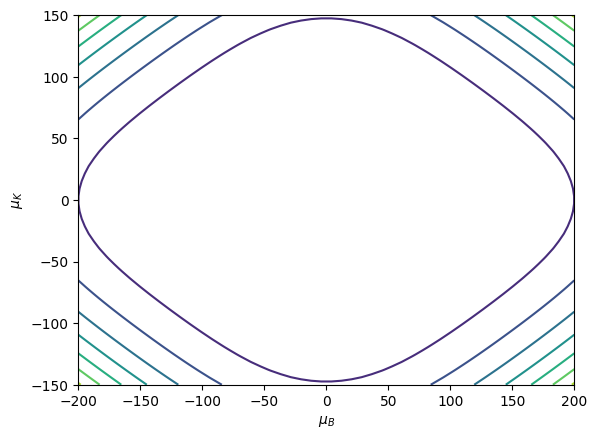

In [22]:
muK = np.linspace(-150,150,50)
muB = np.linspace(-200,200,50)

muK_grid, muB_grid = np.meshgrid(muK, muB)

P_QM = ((muB_grid/3 + muK_grid/2)**4 + (muB_grid/3 - muK_grid/2)**4 + (muB_grid/3)**4) * 3/(12*np.pi**2) #- (muB_grid)**4/(1*12*np.pi**2)
contours = plt.contour(muB_grid, muK_grid, P_QM)
plt.xlabel(r"$\mu_B$")
plt.ylabel(r"$\mu_K$")
plt.show()

it's easy to see that the maximum value for $\mu_K^{Q^*}$ is $\mu_B/(4/3)\simeq \mu_B/1.3>\mu_B/1.732$, so there should be a reigin such that Eq.(35) holds while Eq.(38) doesn't

Btw, since $m_s\sim 100MeV$, it's better to use the following formula for QM pressure:
$$
P_{QM} = \frac{3(\mu_u^4 + \mu_d^4)}{12\pi^2} + 3P_f(\mu_s) - B
$$
but for first approximation, I just take $m_s = 0$ and analyzed

# Prior ro Apr 11

Starting point is not good, leading to lots of confusions..., so for next week:

* use mathematica to start from (35) see if I can get (38) <p>
* with non-interacting QM, NM model try to repproduce what's dipicted in the paper

### NM model

$$
P_{NM}(\mu_n,\mu_p,\mu_e) = P_f(\mu_n) + P_f(\mu_p) + \frac{\mu_e^4}{12\pi^2}
$$
we have the following relation among chemical potentials: 
$$
\left\{
\begin{aligned}
& \mu_n = \mu_B + \mu_K \\
& \mu_p = \mu_B + \frac{1}{2}\mu_K + \mu_Q \\
& \mu_e = -\mu_Q
\end{aligned}
\right.
$$
In addition, the neutralality implies $n_Q = n_p - n_e = 0$, which gives one constraints, so $P_{NM}$ can be expressed as a function of $\mu_B, \mu_K$ (ignore complex roots)
$$
\mu_e^2 + m_B^2 = \left(\mu_B + \frac{\mu_K}{2} - \mu_e\right)^2 
$$

(* T=0 limit of pressure formula *)
(*Result = FullSimplify[Integrate[w^2 Log[1 + Exp[-(w-mu)/T]], {w,0,Infinity}, Assumptions -> {mu>0, T>0}]]*)

Subscript[n,p] = Subscript[k,p]^3 / (3 Pi^2) /. Subscript[k,p] -> Sqrt[(\[Mu]B + (*\[Mu]K/2*) - \[Mu]e)^2 - m^2]
Subscript[n,e] = Subscript[k,e]^3 / (3 Pi^2) /. Subscript[k,e] -> \[Mu]e

eqn = Subscript[n,p] == Subscript[n,e]

result = Simplify[Solve[eqn, \[Mu]e]]

Print[result]


which can be solved in a closed form

In [18]:
from scipy.optimize import fsolve

def P_f(mu, m):
    k_F = np.sqrt(mu**2 - m**2)
    return ( (2*k_F**3 - 3*m**2*k_F)*mu + 3*m**4*np.log((k_F+mu)/m) )/(24*np.pi**2)

m_B = 939  # nucleon mass 939 MeV

muK = np.linspace(-50,50,50)
muB = np.linspace(990,1200,50)

muK_grid, muB_grid = np.meshgrid(muK, muB)

# Function to solve: equation in mu_e
def equation(mu_e, mu_B, mu_K, m_B):
    lhs = mu_e**2 + m_B**2
    rhs = (mu_B + mu_K / 2 - mu_e)**2
    return lhs - rhs

'''
# Empty array to store mu_e solutions
muE_grid = np.zeros_like(muB_grid)

# Solve at each grid point
for i in range(muB_grid.shape[0]):
    for j in range(muB_grid.shape[1]):
        mu_B = muB_grid[i, j]
        mu_K = muK_grid[i, j]
        guess = mu_B  # good initial guess
        sol = fsolve(equation, guess, args=(mu_B, mu_K, m_B))
        muE_grid[i, j] = sol[0]
'''
numerator = muB_grid**2 + (muK_grid**2) / 4 + muB_grid * muK_grid - m_B**2
denominator = 2 * (muB_grid + muK_grid / 2)

# Compute mu_e, handling division by zero
with np.errstate(divide='ignore', invalid='ignore'):
    muE_grid = numerator / denominator
    muE_grid[np.isnan(muE_grid) | np.isinf(muE_grid)] = np.nan  # clean up bad values
        

muQ_grid = -muE_grid
mun_grid = muB_grid + muK_grid
mup_grid = muB_grid + muQ_grid + muK_grid/2 

# check if there's negative value entering square roots defined in P_f()
mask_invalid_mun = (mun_grid**2 - m_B**2) < 0
mask_invalid_mup = (mup_grid**2 - m_B**2) < 0

print("Invalid mun:", np.any(mask_invalid_mun))
print("Invalid mup:", np.any(mask_invalid_mup))

# Optionally print where:
print("Locations (i,j) where mun_grid^2 < m_B^2:")
print(np.argwhere(mask_invalid_mun))

print("Locations (i,j) where mup_grid^2 < m_B^2:")
print(np.argwhere(mask_invalid_mup))

Invalid mun: False
Invalid mup: False
Locations (i,j) where mun_grid^2 < m_B^2:
[]
Locations (i,j) where mup_grid^2 < m_B^2:
[]


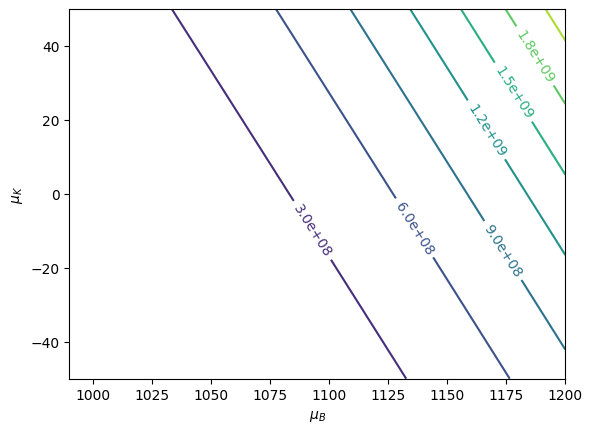

In [19]:
P_NM = P_f(mun_grid, m_B) + P_f(mup_grid, m_B) + muE_grid**4 / (12*np.pi**2)

contours = plt.contour(muB_grid, muK_grid, P_NM)
plt.clabel(contours, inline=True, fontsize=10, fmt="%.1e")
plt.xlabel(r"$\mu_B$")
plt.ylabel(r"$\mu_K$")
plt.show()

### NM model without Kaon dependence

In [5]:
from scipy.optimize import fsolve

def P_f(mu, m):
    k_F = np.sqrt(mu**2 - m**2)
    return ( (2*k_F**3 - 3*m**2*k_F)*mu + 3*m**4*np.log((k_F+mu)/m) )/(24*np.pi**2)

m_B = 939  # nucleon mass 939 MeV

muK = np.linspace(-50,50,50)
muB = np.linspace(940, 1050,50)

muK_grid, muB_grid = np.meshgrid(muK, muB)

muE_grid = (muB_grid**2 - m_B**2)/(2*muB_grid)

muQ_grid = -muE_grid
mun_grid = muB_grid 
mup_grid = muB_grid + muQ_grid 

# check if there's negative value entering square roots defined in P_f()
mask_invalid_mun = (mun_grid**2 - m_B**2) < 0
mask_invalid_mup = (mup_grid**2 - m_B**2) < 0

print("Invalid mun:", np.any(mask_invalid_mun))
print("Invalid mup:", np.any(mask_invalid_mup))

# Optionally print where:
print("Locations (i,j) where mun_grid^2 < m_B^2:")
print(np.argwhere(mask_invalid_mun))

print("Locations (i,j) where mup_grid^2 < m_B^2:")
print(np.argwhere(mask_invalid_mup))

Invalid mun: False
Invalid mup: False
Locations (i,j) where mun_grid^2 < m_B^2:
[]
Locations (i,j) where mup_grid^2 < m_B^2:
[]


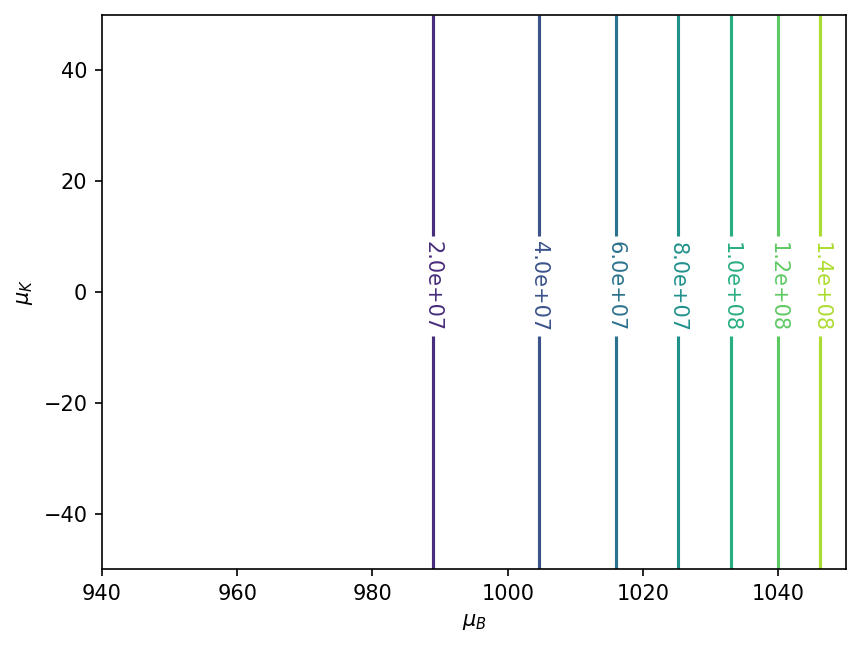

In [6]:
P_NM = P_f(mun_grid, m_B) + P_f(mup_grid, m_B) + muE_grid**4 / (12*np.pi**2)

contours = plt.contour(muB_grid, muK_grid, P_NM)
plt.clabel(contours, inline=True, fontsize=10, fmt="%.1e")
plt.xlabel(r"$\mu_B$")
plt.ylabel(r"$\mu_K$")
plt.show()

### QM model

$$
P_{QM}(\mu_B,\mu_K) = \frac{3(\mu_u^4 + \mu_d^4)}{12\pi^2} + 3P_f(\mu_s) - B = \frac{3}{12 \pi^2} \left[ \left( \frac{\mu_B}{3} + \frac{\mu_K}{2} \right)^4 + \left( \frac{\mu_B}{3} \right)^4 \right] + 3P_f\left( \frac{\mu_B}{3} - \frac{\mu_K}{2} \right) - B
$$
there're free parameters here: the bag constant $B$, and $m_s$ around 100MeV

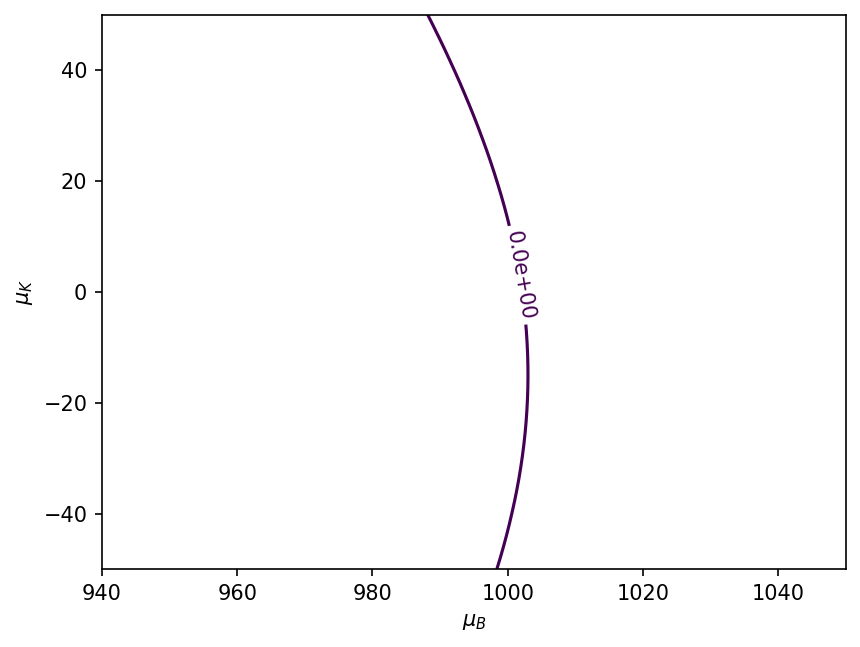

In [7]:
B = (170)**4
m_s = 100
muK = np.linspace(-50,50,50)
muB = np.linspace(940, 1050,50)
muK_grid, muB_grid = np.meshgrid(muK, muB)

P_QM = ((muB_grid/3 + muK_grid/2)**4 + (muB_grid/3)**4) * 3/(12*np.pi**2) + 3*P_f(muB_grid/3 - muK_grid/2, m_s) - B

contours = plt.contour(muB_grid, muK_grid, P_QM-P_NM, levels=[0])
plt.clabel(contours, inline=True, fontsize=10, fmt="%.1e")
plt.xlabel(r"$\mu_B$")
plt.ylabel(r"$\mu_K$")
plt.show()

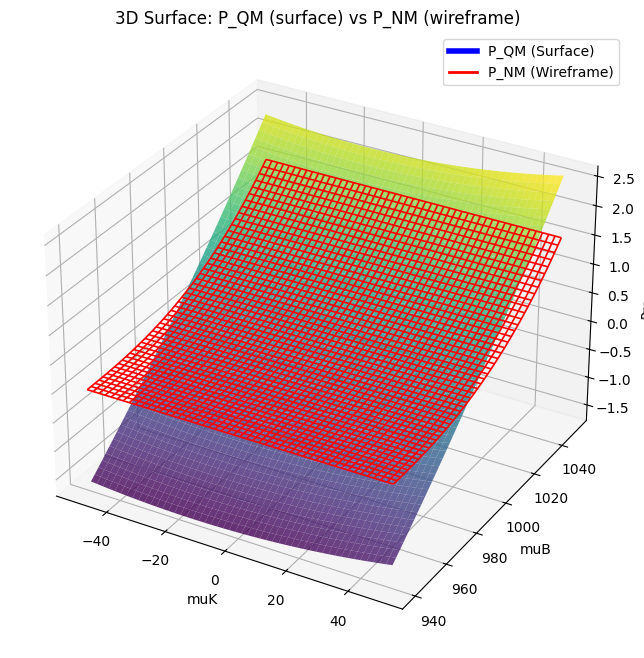

In [135]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Surface for P_QM
surf1 = ax.plot_surface(muK_grid, muB_grid, P_QM, cmap='viridis', alpha=0.8, label='P_QM')

# Wireframe for P_NM
wire2 = ax.plot_wireframe(muK_grid, muB_grid, P_NM, color='red', linewidth=1.2, label='P_NM')

ax.set_xlabel('muK')
ax.set_ylabel('muB')
ax.set_zlabel('Pressure')
ax.set_title('3D Surface: P_QM (surface) vs P_NM (wireframe)')

# Custom legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color='blue', lw=4, label='P_QM (Surface)'),
    Line2D([0], [0], color='red', lw=2, label='P_NM (Wireframe)')
]
ax.legend(handles=legend_elements)

plt.show()

so to see what's going on, take a slice of this surface plot for $\mu_K=0$, i.e. the equilibriated QM and NM

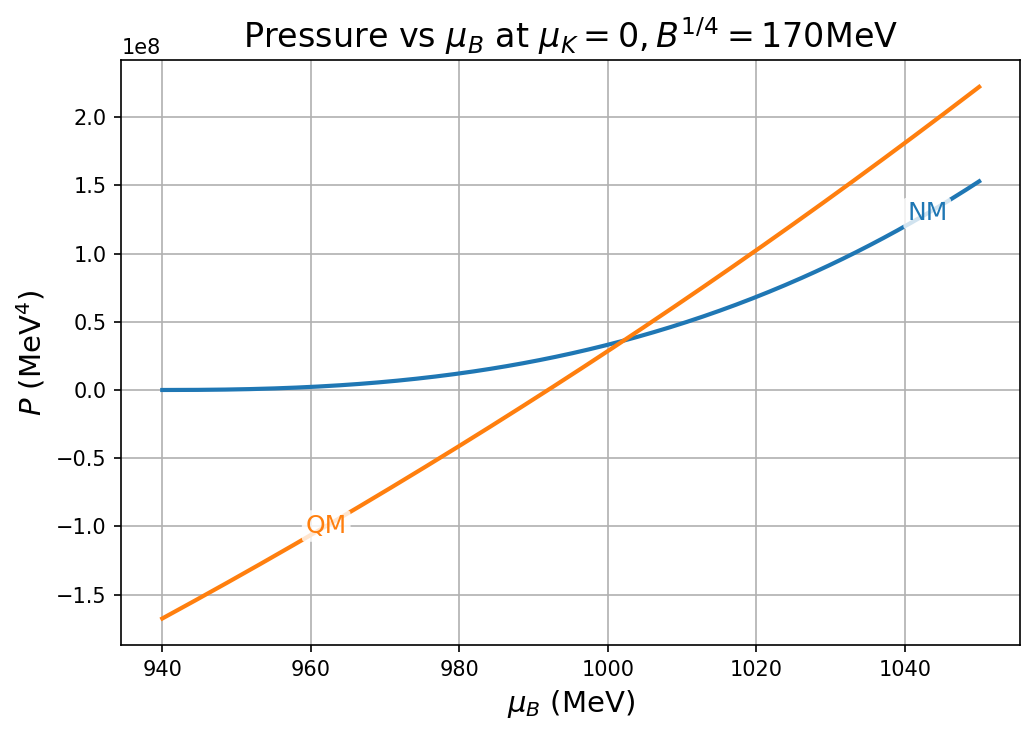

In [7]:
import numpy as np
import matplotlib.pyplot as plt

def P_f(mu, m):
    k_F = np.sqrt(mu**2 - m**2)
    return ((2*k_F**3 - 3*m**2*k_F)*mu + 3*m**4*np.log((k_F+mu)/m)) / (24*np.pi**2)

# Constants
m_B = 939
m_s = 100
B_one_forth = 170  # 280 for muB/2 in QM
B = B_one_forth**4

# mu_B range
muB = np.linspace(940, 1050, 300)

# NM
muE = (muB**2 - m_B**2) / (2 * muB) # solved using MMA, this corresponds to the real solution
muQ = -muE
mun = muB
mup = muB + muQ
P_NM = P_f(mun, m_B) + P_f(mup, m_B) + muE**4 / (12 * np.pi**2)

# QM
mu_u = muB / 3
mu_d = muB / 3
mu_s = muB / 3
P_QM = (mu_u**4 + mu_d**4) * 3 / (12 * np.pi**2) + 3 * P_f(mu_s, m_s) - B

# Plot
plt.figure(figsize=(7, 5))
plt.plot(muB, P_NM, lw=2, color='tab:blue')
plt.plot(muB, P_QM, lw=2, color='tab:orange')

# Tight background box
boxprops = dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='none', alpha=0.8)

plt.text(muB[280], P_NM[280], "NM", fontsize=12, color='tab:blue', ha='center', va='center', bbox=boxprops)
plt.text(muB[60],  P_QM[60],  "QM", fontsize=12, color='tab:orange', ha='center', va='center', bbox=boxprops)

plt.xlabel(r'$\mu_B$ (MeV)', fontsize=14)
plt.ylabel(r'$P$ (MeV$^4$)', fontsize=14)
plt.title(r'Pressure vs $\mu_B$ at $\mu_K = 0, B^{1/4}=$'+str(B_one_forth)+'MeV', fontsize=16)
plt.grid(True)
plt.tight_layout()
plt.show()

Before I got seemingly correct result because I take $\mu_n = \mu_p = \mu_B/2$, which is wrong. That we get this result is due to $\mu_B/3$ supression in QM. 

### Questions & findings

* If we added kaon-ness dependence to NM, then the isobar for NM pressure is tilted, and we the weak equilibrium: $\mu_n = \mu_p + \mu_e$ would no longer be valid. So probably we need to add hyperons:
    * $\Lambda^0 = [uds]$, and $\Sigma^0 = [uds]$, where their chemical potential $\mu = \mu_B$
    * $\Sigma^{+} = [uus]$, where $\mu_{\Sigma^+} = \mu_B - \frac{\mu_K}{2}$
    * $\Sigma^{-} = [dds]$, where $\mu_{\Sigma^-} = \mu_B + \frac{\mu_K}{2}$
    * all of the above has mass around 1.1GeV
    * still working on which baryon (with s quark) could be present, and it's beta equilibrium condition
* a lot of constraints actually comes from there shouldn't be negative entries to $\sqrt{\mu^2 - m^2}$
* if we don't consider kaon-ness in NM, then have to adjust bag constant $B\sim5.5\times 10^8$, corresponds to $B^{1/4}\sim 153$MeV
* and the slope of NM in $\mu_B - P$ plain is larger than QM, which is nonsence; so the non-interacting NM and QM model can't capture reality; so probably time for learning new things and looking into more sophiscated models
* I used MMA to rederive the formula, so yeah, there seems to be a sign error
* Also thought about is there an upper limit. From Olinto's claim: $a<0.5$, I looked into her paper's 2nd reference (Farhi, Jaffe 1984), which set upper limit based on stability of SQM: energy per baryon $E/A$ for SQM should be smaller than energy per baryon for iron nuclei, which is 930MeV. 

In [73]:
np.sqrt(np.sqrt(5.5e+8))

np.float64(153.1407156804393)

# Prior to Apr 22

looking for critical point

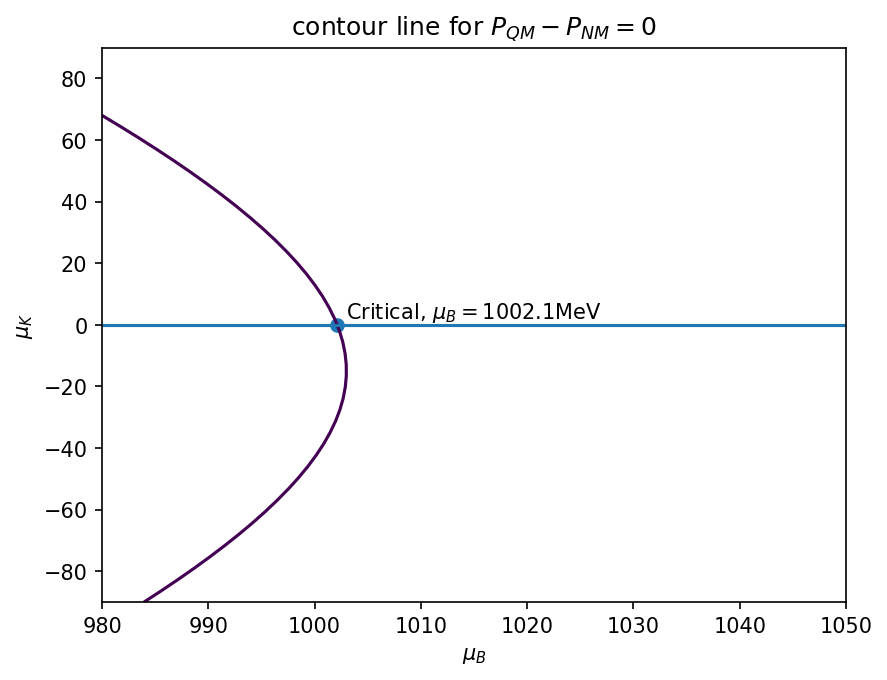

P_{crit} =  36102138.15596604


In [32]:
m_s = 100
m_B = 939
B_one_forth = 170  # 280 for muB/2 in QM
B = B_one_forth**4
muK = np.linspace(-90,90,50)
muB = np.linspace(980, 1050,50)
muK_grid, muB_grid = np.meshgrid(muK, muB)

def P_f(mu, m):
    k_F = np.sqrt(mu**2 - m**2)
    return ((2*k_F**3 - 3*m**2*k_F)*mu + 3*m**4*np.log((k_F+mu)/m)) / (24*np.pi**2)

def PQM(muB, muK, B):
    return ((muB/3 + muK/2)**4 + (muB/3)**4) * 3/(12*np.pi**2) + 3*P_f(muB/3 - muK/2, m_s) - B
    
def PNM(muB):
    muE = (muB**2 - m_B**2) / (2 * muB) # solved using MMA, this corresponds to the real solution
    muQ = -muE
    mun = muB
    mup = muB + muQ
    return P_f(mun, m_B) + P_f(mup, m_B) + muE**4 / (12 * np.pi**2)

PQM_wrap = lambda Mu: PQM(Mu[0], Mu[1], B)


P_QM = PQM(muB_grid, muK_grid, B) #((muB_grid/3 + muK_grid/2)**4 + (muB_grid/3)**4) * 3/(12*np.pi**2) + 3*P_f(muB_grid/3 - muK_grid/2, m_s) - B
P_NM = PNM(muB_grid)

contours = plt.contour(muB_grid, muK_grid, P_QM - P_NM, levels=[0])
#contours = plt.contour(muB_grid, muK_grid, P_QM, levels=[0])
plt.plot(muB, np.zeros(len(muB)))
#plt.plot(1002.1*np.ones(len(muK)), muK)
plt.scatter(1002.1,0)
plt.text(1003, 2, r"Critical, $\mu_B = 1002.1$MeV")
#plt.clabel(contours, inline=True, fontsize=10, fmt="%.1e")
plt.title(r"contour line for $P_{QM} - P_{NM} = 0$")
plt.xlabel(r"$\mu_B$")
plt.ylabel(r"$\mu_K$")
plt.show()

P_crit = PQM(1002.1, 0, B)
print(r"P_{crit} = ", P_crit)

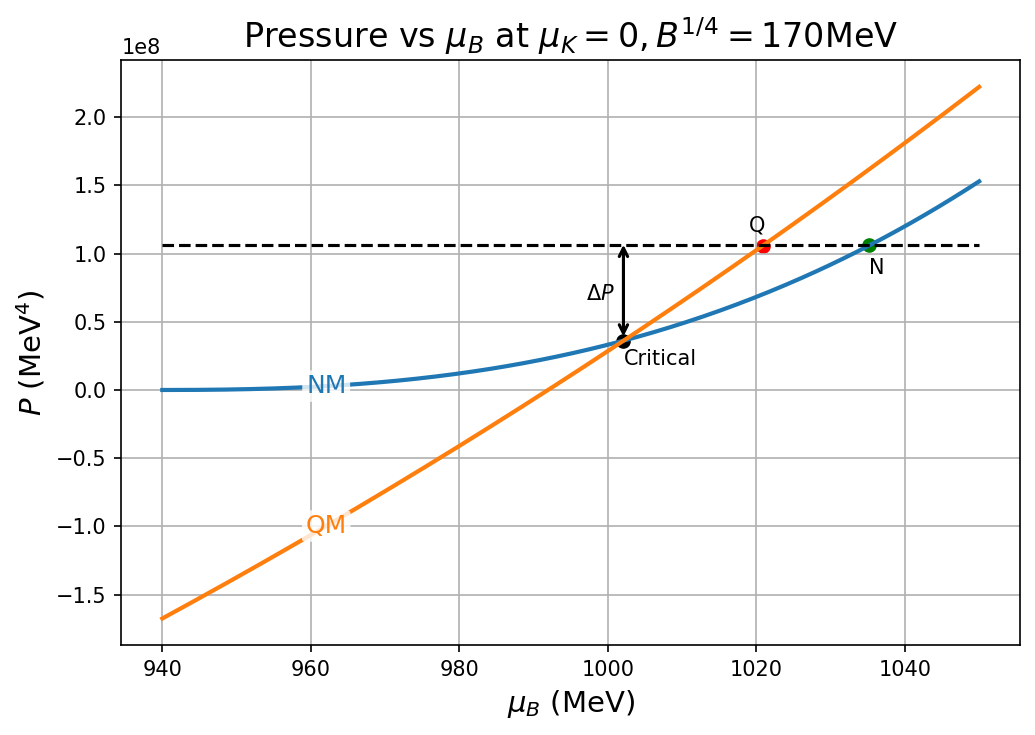

In [31]:
import numpy as np
import matplotlib.pyplot as plt

def P_f(mu, m):
    k_F = np.sqrt(mu**2 - m**2)
    return ((2*k_F**3 - 3*m**2*k_F)*mu + 3*m**4*np.log((k_F+mu)/m)) / (24*np.pi**2)

# Constants
Delta_P = 7e+7
m_B = 939
m_s = 100
B_one_forth = 170  # 280 for muB/2 in QM
B = B_one_forth**4

# mu_B range
muB = np.linspace(940, 1050, 300)

# NM
muE = (muB**2 - m_B**2) / (2 * muB) # solved using MMA, this corresponds to the real solution
muQ = -muE
mun = muB
mup = muB + muQ
P_NM = P_f(mun, m_B) + P_f(mup, m_B) + muE**4 / (12 * np.pi**2)

# QM
mu_u = muB / 3
mu_d = muB / 3
mu_s = muB / 3
P_QM = (mu_u**4 + mu_d**4) * 3 / (12 * np.pi**2) + 3 * P_f(mu_s, m_s) - B

# Plot
plt.figure(figsize=(7, 5))
plt.plot(muB, P_NM, lw=2, color='tab:blue')
plt.plot(muB, P_QM, lw=2, color='tab:orange')

# Tight background box
boxprops = dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='none', alpha=0.8)

plt.text(muB[60], P_NM[60], "NM", fontsize=12, color='tab:blue', ha='center', va='center', bbox=boxprops)
plt.text(muB[60],  P_QM[60],  "QM", fontsize=12, color='tab:orange', ha='center', va='center', bbox=boxprops)
plt.scatter(1002.1, P_crit, c='k') # 3.6e+7
plt.text(1002.1, 0.5*P_crit, r"Critical")
plt.plot(muB, (P_crit + Delta_P)*np.ones(len(muB)), 'k--')
plt.scatter(1020.89, PQM(1020.89, 0, B), c='r')
plt.text(1019, PQM(1020.89,0,B)*1.1, r"Q")
plt.scatter(1035.2, PNM(1035.2), c='g')
plt.text(1035.2, 0.8*PNM(1035.2), r"N")

plt.annotate(
    '', 
    xy=(1002.1, PQM(1002.1, 0, B)), 
    xytext=(1002.1, P_crit+Delta_P*1.05
           ),
    arrowprops=dict(arrowstyle='<->', color='black', lw=1.5),
)
# Optional label for the arrow
plt.text(1002.1-5, (P_crit + Delta_P)/1.5, r'$\Delta P$', va='center')


plt.xlabel(r'$\mu_B$ (MeV)', fontsize=14)
plt.ylabel(r'$P$ (MeV$^4$)', fontsize=14)
plt.title(r'Pressure vs $\mu_B$ at $\mu_K = 0, B^{1/4}=$'+str(B_one_forth)+'MeV', fontsize=16)
plt.grid(True)
plt.tight_layout()
plt.show()

isobar for quark matter at $P = P_{crit} + \Delta P$

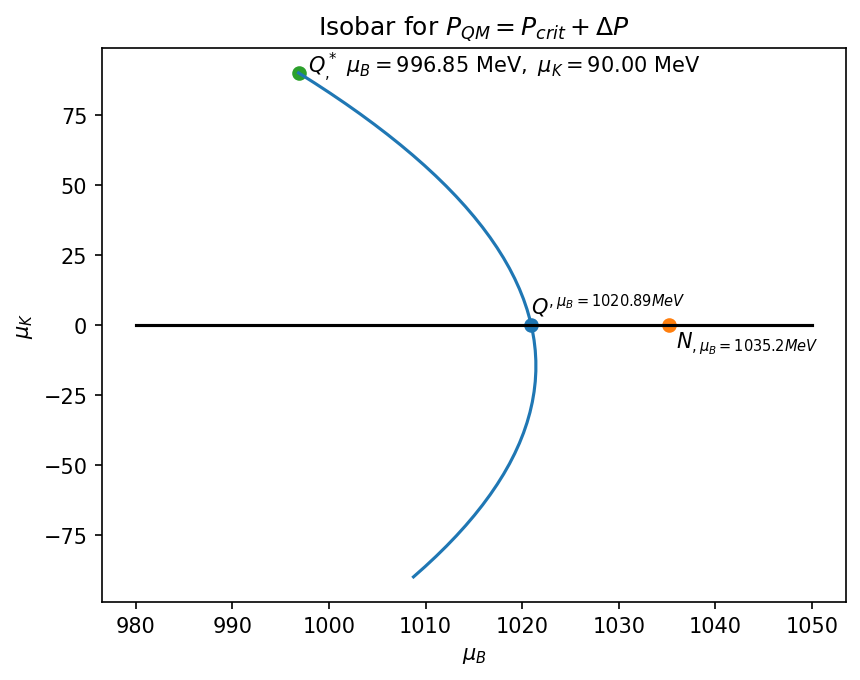

In [23]:
B = (170)**4
m_s = 100
muK = np.linspace(-90,90,50)
muB = np.linspace(980, 1050,50)
muK_grid, muB_grid = np.meshgrid(muK, muB)
Delta_P = 7e+7

def PQM(muB, muK, B):
    return ((muB/3 + muK/2)**4 + (muB/3)**4) * 3/(12*np.pi**2) + 3*P_f(muB/3 - muK/2, m_s) - B
    
def PNM(muB):
    muE = (muB**2 - m_B**2) / (2 * muB) # solved using MMA, this corresponds to the real solution
    muQ = -muE
    mun = muB
    mup = muB + muQ
    return P_f(mun, m_B) + P_f(mup, m_B) + muE**4 / (12 * np.pi**2)

PQM_wrap = lambda Mu: PQM(Mu[0], Mu[1], B)


P_QM = PQM(muB_grid, muK_grid, B) #((muB_grid/3 + muK_grid/2)**4 + (muB_grid/3)**4) * 3/(12*np.pi**2) + 3*P_f(muB_grid/3 - muK_grid/2, m_s) - B
P_NM = PNM(muB_grid)

# need to extract the contour curve for later use, such as calculating baryon density and kaon density at each point on the contour
def extract_contour_coords(X, Y, Z, level):
    fig, ax = plt.subplots()
    contour_obj = ax.contour(X, Y, Z, levels=[level])
    # Directly access the paths from the contour object
    paths = []
    for c in contour_obj.get_paths():
        paths.append(c.vertices)
    plt.close(fig)  # Close the plot if you only want data
    if not paths:
        raise RuntimeError(f"No contours found at level {level}")
    return paths[0][:, 0], paths[0][:, 1]

# plot contour
muB_contour_coor, muK_contour_coor = extract_contour_coords(muB_grid, muK_grid, P_QM, P_crit + Delta_P)
plt.plot(muB_contour_coor, muK_contour_coor)

# point Q
plt.plot(muB, np.zeros(len(muB)), 'k')
#plt.plot(1020.89*np.ones(len(muK)), muK)
plt.scatter(1020.89,0)
plt.text(1020.9, 4, r"$Q^{, \mu_B = 1020.89 MeV}$")

# point N, taken to be the isobar for NM pressure = P_crit + Delta_P
#plt.contour(muB_grid, muK_grid, P_NM, levels = [P_crit + Delta_P])
#plt.plot(1035.2*np.ones(len(muK)), muK)
plt.scatter(1035.2,0)
plt.text(1035.9, -8, r"$N_{, \mu_B = 1035.2 MeV}$")

# point Q star
#plt.plot(1016*np.ones(len(muK)), muK)
plt.scatter(muB_contour_coor[-1],muK_contour_coor[-1])
plt.text(muB_contour_coor[-1]+1, muK_contour_coor[-1], rf"$Q^*_,\ \mu_B = {muB_contour_coor[-1]:.2f}\ \mathrm{{MeV}},\ \mu_K = {muK_contour_coor[-1]:.2f}\ \mathrm{{MeV}}$")

plt.xlabel(r"$\mu_B$")
plt.ylabel(r"$\mu_K$")
plt.title(r"Isobar for $P_{QM} = P_{crit} + \Delta P$")
plt.show()

compare $\mu_B^N$ and the average chemical potential at $Q^*$ point: $\overline{\mu}_B = \mu_B^{Q^*} + \frac{n_K^{Q^*}}{n_B^{Q^*}}\mu_K^{Q^*}$. We see in extreme cases, $\overline{\mu}_B > \mu_B^N$ !!!

In [25]:
# calculate baryon density and kaon density at Q*
from scipy.optimize import approx_fprime

muB_N = 1035.2
muB_Qstar = muB_contour_coor[-1]
muK_Qstar = muK_contour_coor[-1]
Qstar = np.array([muB_Qstar, muK_Qstar])
epsilon = np.sqrt(np.finfo(float).eps) # step size
grad = approx_fprime(Qstar, PQM_wrap, epsilon) # calculate n=∂P/∂mu
nB_Qstar = grad[0]
nK_Qstar = grad[1]

mu_average = muB_Qstar + nK_Qstar * muK_Qstar / nB_Qstar
print("average chemical potential = ", mu_average, " | chemical potential at point N = ", muB_N)

average chemical potential =  1038.8163245036349  | chemical potential at point N =  1035.2


Text(35, 1035.6, '$\\mu_B^N$')

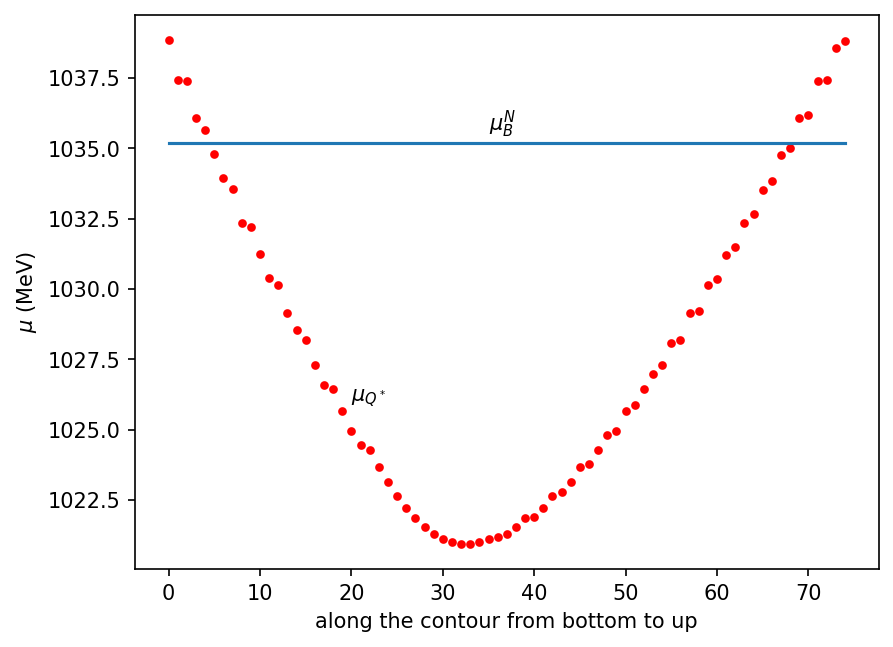

In [29]:
# search for every point on the contour curve and see which Q star the average chemical potential exceeds that for N
epsilon = np.sqrt(np.finfo(float).eps)
mu_average = []

for i in range(len(muB_contour_coor)):
    muB_Qstar = muB_contour_coor[i]
    muK_Qstar = muK_contour_coor[i]
    Qstar = np.array([muB_Qstar, muK_Qstar])
    grad = approx_fprime(Qstar, PQM_wrap, epsilon) # calculate n=∂P/∂mu
    nB_Qstar = grad[0]
    nK_Qstar = grad[1]
    mu_average.append( muB_Qstar + nK_Qstar * muK_Qstar / nB_Qstar)

plt.scatter([i for i in range(len(mu_average))], mu_average, c='r', s=10)
plt.plot([i for i in range(len(mu_average))], muB_N*np.ones(len(mu_average)))
plt.xlabel("along the contour from bottom to up")
plt.ylabel(r"$\mu$ (MeV)")
plt.text(20, 1026, r"$\mu_{Q^*}$")
plt.text(35, 1035.6, r"$\mu_B^N$")

so based on the current model, the idea that $\overline{\mu}_B < \mu_B^N$ indeed should give a upper limit on how far can $Q^*$ jump, but only relatively far points are excluded; this means we need to take higher order Taylor expansion in the derivation to see the firm constraints

Follow up steps: include electrons in QM, can also include interactions

I've been reading papers, two interesting things to discuss:
* gauge/gravity duality
* nucleation of strangelets in hot environment, like spiral and merger event, and NM to SQM burning in post merger
* uploaded something to overleaf

# Old code that has wrong algebra

In [22]:
def Omega2(mu1, T1, a):
    Omega2 = np.cbrt((300**3 * mu1**2 / T1**5)) * 1/(np.cbrt(0.35))**5 * (mu1/300)**5 * (a**4 + 18*3.1415**2 * (T1/mu1)**2 * a**2)
    return Omega2

In [23]:
2.61*np.sqrt(Omega2(360, 100, 0.1))

np.float64(9.708695766459288)

In [13]:
step = 50
mu = np.linspace(310,400,step)
T = np.linspace(10,100,step)

Mu, TT = np.meshgrid(mu,T)

aQ = 0.1
Omega = np.sqrt((Omega2(Mu,TT,aQ)))
V = 2.61*Omega

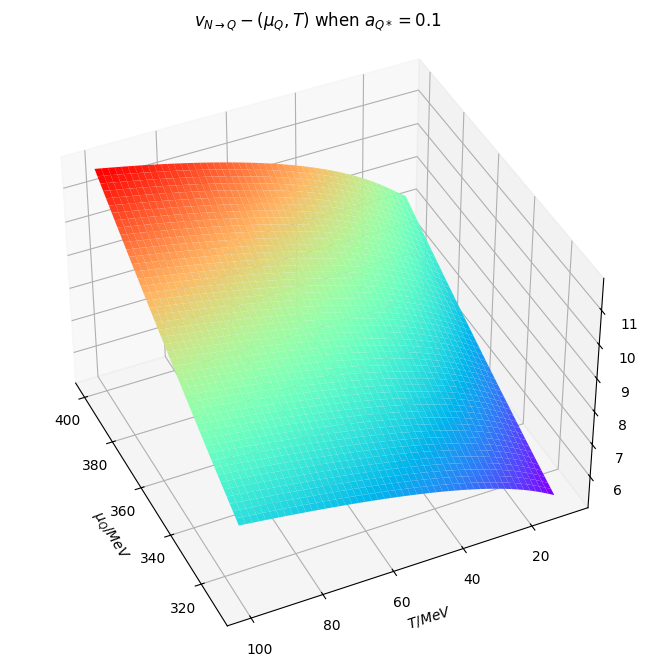

In [14]:
fig = plt.figure(figsize=(10, 8))
#ax.zaxis.label.set_visible(True)
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(Mu, TT, V, cmap='rainbow')
ax.set_xlabel(r'$\mu_Q/MeV$')
ax.set_ylabel(r'$T/MeV$')
ax.set_zlabel('m/s', labelpad=15)
ax.set_title(r'$v_{N\to Q}-(\mu_Q, T)$ when $a_{Q*} = $'+str(aQ))

# Force label visibility
ax.zaxis.label.set_visible(True)

# Adjust view
ax.view_init(elev=40, azim=155)

plt.show(block = True)

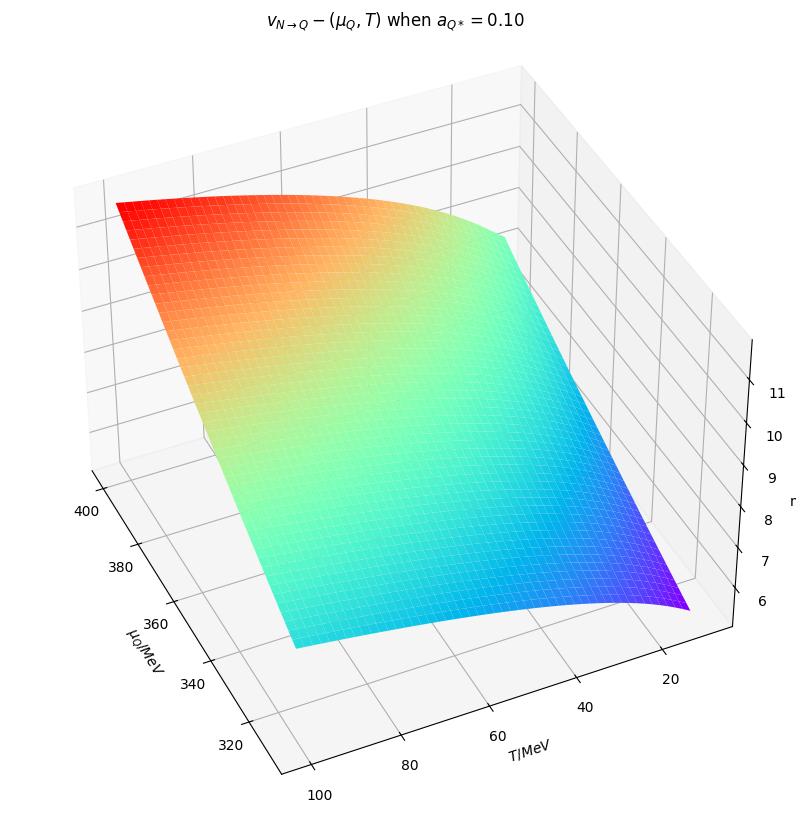

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from mpl_toolkits.mplot3d import Axes3D

# Define parameters
step = 50
mu = np.linspace(310,400,step)
T = np.linspace(10,100,step)
Mu, TT = np.meshgrid(mu, T)

def update(frame):
    ax.clear()
    aQ = np.linspace(0.001, 0.1, num=100)[frame]  # Varying aQ over frames
    Omega = np.sqrt(Omega2(Mu, TT, aQ))
    V = 2.61 * Omega
    ax.plot_surface(Mu, TT, V, cmap='rainbow')
    ax.set_xlabel(r'$\mu_Q/MeV$')
    ax.set_ylabel(r'$T/MeV$')
    ax.set_zlabel('m/s')
    ax.set_title(r'$v_{N\to Q}-(\mu_Q, T)$ when $a_{Q*} = $' + f'{aQ:.2f}')
    ax.zaxis.label.set_visible(True)
    ax.view_init(elev=40, azim=155)

# Set up figure and 3D plot
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

# Create animation
ani = animation.FuncAnimation(fig, update, frames=100, interval=50)

# Save animation as GIF
save_path = "/Users/janshao/Downloads/3D_animation.gif"
ani.save(save_path, writer='pillow', fps=10)

plt.show()


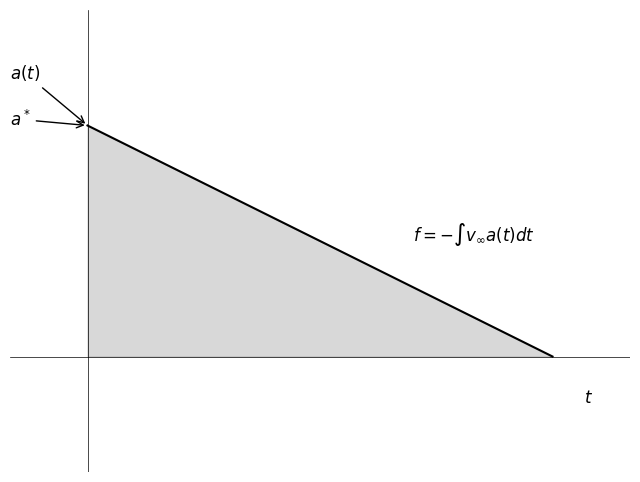

In [23]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
a_star = 1
a_max = 3

# Define the function a(t)
def a(t):
    return a_star * (1 - t / a_max)

# t values for the plot
t = np.linspace(0, a_max, 300)
a_values = a(t)

# Plot
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(t, a_values, label=r'$a(t)$', color='black')
ax.fill_between(t, a_values, 0, where=(t <= a_max), color='gray', alpha=0.3, label='Shaded Area')

# Arrows and labels
ax.annotate(r'$a(t)$', xy=(0, a_star), xytext=(-0.5, a_star + 0.2),
            arrowprops=dict(facecolor='black', arrowstyle='->'), fontsize=12)

ax.annotate(r'$a^*$', xy=(0, a_star), xytext=(-0.5, a_star),
            arrowprops=dict(facecolor='black', arrowstyle='->'), fontsize=12)

ax.annotate(r'$t$', xy=(a_max, 0), xytext=(a_max + 0.2, -0.2), fontsize=12)
ax.annotate(r'$f = -\int v_{\infty} a(t) dt$', xy=(a_max*0.7, a_star*0.5), fontsize=12)

# Remove axis numbers and grid
ax.set_xticks([])
ax.set_yticks([])

# Remove the box (spines)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)

# Axes lines
ax.axhline(0, color='black', linewidth=0.5)
ax.axvline(0, color='black', linewidth=0.5)

# Set limits
ax.set_xlim(-0.5, a_max + 0.5)
ax.set_ylim(-0.5, a_star + 0.5)

# Show the plot
plt.show()

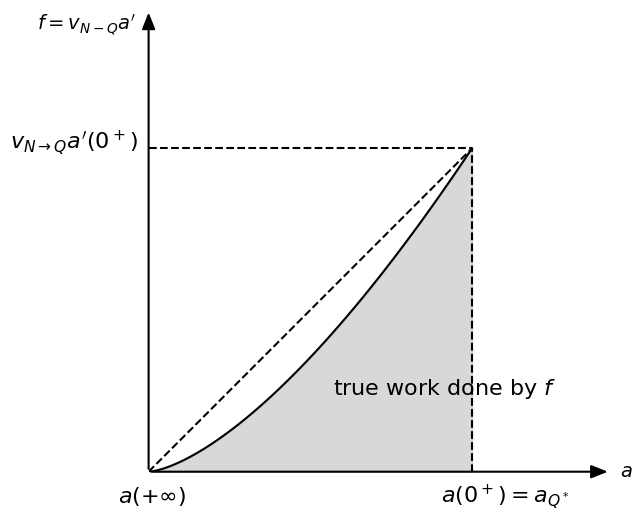

In [86]:
import matplotlib.pyplot as plt
import os

# Create the plot
fig, ax = plt.subplots(figsize=(8, 6))

# Remove all spines (the box)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)

limi = 3

# Draw only the x and y axes
#ax.axhline(0, color='black', linewidth=2)  # x-axis
#ax.axvline(0, color='black', linewidth=2)  # y-axis
ax.annotate('', xy=(limi, 0), xytext=(0, 0),
            arrowprops=dict(arrowstyle='-|>,head_width=0.4,head_length=1.0', linewidth=1.5, color='black'))
ax.annotate('', xy=(0, limi), xytext=(0, 0),
            arrowprops=dict(arrowstyle='-|>,head_width=0.4,head_length=1.0', linewidth=1.5, color='black'))
ax.text(limi+0.1, 0, r'$a$', fontsize=14, ha='center', va='center')
ax.text(-0.4, limi-0.1, r'$f = v_{N-Q}a^\prime$', fontsize=14, ha='center', va='center')


# Remove ticks and labels
ax.set_xticks([])
ax.set_yticks([])

# Set equal aspect ratio for symmetry
ax.set_aspect('equal')

x = np.linspace(0,0.7*limi,100)
y = x**(3/2)
ax.plot(x, 0.7*limi*y/y.max(), c='black')
ax.plot(0.7*limi*np.ones(100), x, c='black', linestyle='--')
ax.plot(x, 0.7*limi*np.ones(100), c='black', linestyle='--')
ax.plot(x,x,c='black', linestyle='--')

ax.fill_between(x, 0, 0.7*limi*y/y.max(), color='gray', alpha=0.3)

# Set limits
ax.set_xlim(0, limi)
ax.set_ylim(0, limi)

ax.text(-0.2,-0.2,r"$a(+\infty)$", fontsize=16)
ax.text(0.7*limi-0.2, -0.2, r"$a(0^+) = a_{Q^*}$", fontsize=16)
ax.text(-0.9, 0.7*limi, r"$v_{N\to Q}a^\prime(0^+)$", fontsize=16)
ax.text(1.2,0.5,r"true work done by $f$",fontsize=16)

downloads_path = os.path.expanduser("/Users/janshao/Downloads/")

# Save the figure
plt.savefig(os.path.join(downloads_path, "true_work.pdf"), dpi=300)  # Increase DPI as needed

# Show the plot
plt.show()

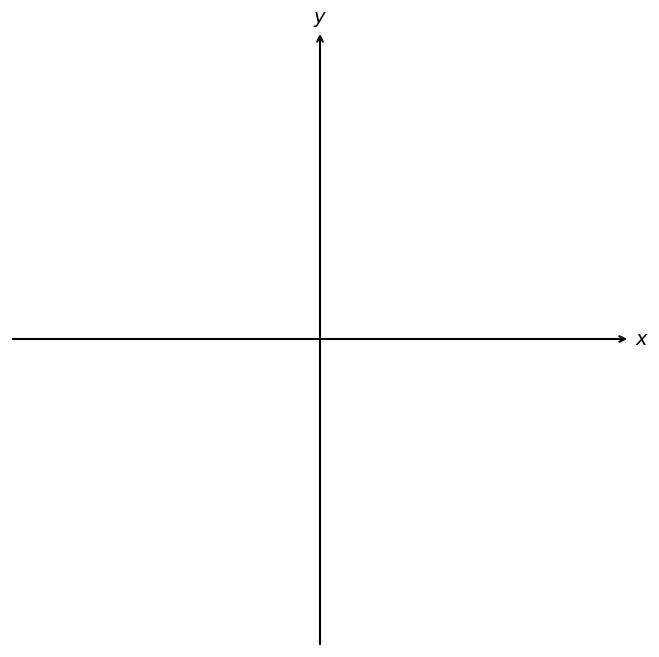

In [45]:
import matplotlib.pyplot as plt

# Create the plot
fig, ax = plt.subplots(figsize=(8, 8))

# Remove spines (no box)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)

# Draw x and y axes using annotate for proper arrows
ax.annotate('', xy=(5, 0), xytext=(-5, 0),
            arrowprops=dict(arrowstyle='->', linewidth=1.5, color='black'))
ax.annotate('', xy=(0, 5), xytext=(0, -5),
            arrowprops=dict(arrowstyle='->', linewidth=1.5, color='black'))

# Remove ticks and labels
ax.set_xticks([])
ax.set_yticks([])

# Add text labels for axes
ax.text(5.2, 0, r'$x$', fontsize=14, ha='center', va='center')
ax.text(0, 5.2, r'$y$', fontsize=14, ha='center', va='center')

# Set limits
ax.set_xlim(-5, 5)
ax.set_ylim(-5, 5)

# Show the plot
plt.show()